# Practical 7: Prime Number Checking in N Natural Numbers

### 1. Aim
To identify prime numbers up to 2,500,000 using vectorized trial division comparing Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Partition the range [1, 2,500,000] into 3 contiguous segments.<br>2. Execute vectorized trial division in compiled C releasing the GIL.<br>3. Sequential: check Segment 1 -> Segment 2 -> Segment 3.<br>4. Pool: map across 3 workers in `mp.Pool(3)`.<br>5. Process: spawn 3 independent `mp.Process` instances.<br>6. Thread: launch 3 concurrent `threading.Thread` workers.<br>7. Verify prime count consistency and compare execution times.

### 3. Python Implementation


In [1]:
"""
Practical 7: Prime Number Checking in N Natural Numbers
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def count_primes_task(rng):
    start, end = rng
    nums = np.arange(start, end, dtype=np.int64)
    is_p = (nums > 1)
    if start <= 2 < end:
        is_p[2 - start] = True
    even_mask = (nums % 2 == 0) & (nums != 2)
    is_p[even_mask] = False
    
    limit = int(end**0.5) + 1
    div_sieve = np.ones(limit, dtype=bool)
    div_sieve[:2] = False
    for p in range(2, int(limit**0.5) + 1):
        if div_sieve[p]:
            div_sieve[p*p : limit : p] = False
    primes = np.nonzero(div_sieve)[0]
    primes = primes[primes >= 3]
    
    # Vectorized divisibility check in compiled C (releases GIL)
    for p in primes:
        mask = (nums % p == 0) & (nums != p)
        is_p[mask] = False
    return int(np.count_nonzero(is_p))

def proc_worker(rng, q):
    q.put(count_primes_task(rng))

def thread_worker(rng, results, idx):
    results[idx] = count_primes_task(rng)

def main():
    print("=" * 60)
    print("Practical 7: Prime Number Checking")
    print("=" * 60)
    N = 2_500_000
    step = N // 3
    tasks = [(1, step), (step, 2 * step), (2 * step, N)]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = count_primes_task(tasks[0])
    r2 = count_primes_task(tasks[1])
    r3 = count_primes_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_primes = r1 + r2 + r3
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(count_primes_task, tasks)
    t_pool = time.perf_counter() - t0
    pool_primes = sum(p_res)
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    proc_primes = sum(proc_res)
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    thread_primes = sum(thread_res)
    
    print(f"Total Range: 1 to {N:,}")
    print(f"Verification: Seq={seq_primes:,} | Thread={thread_primes:,}")
    print(f"Results Match: {seq_primes == thread_primes}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Practical 7: Prime Number Checking
Total Range: 1 to 2,500,000
Verification: Seq=183,072 | Thread=183,072
Results Match: True
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.6956 seconds      1.00x
Pool         2.1840 seconds      1.69x
Process      2.1523 seconds      1.72x
Thread       1.6096 seconds      2.30x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process, and Thread with individual color bars.


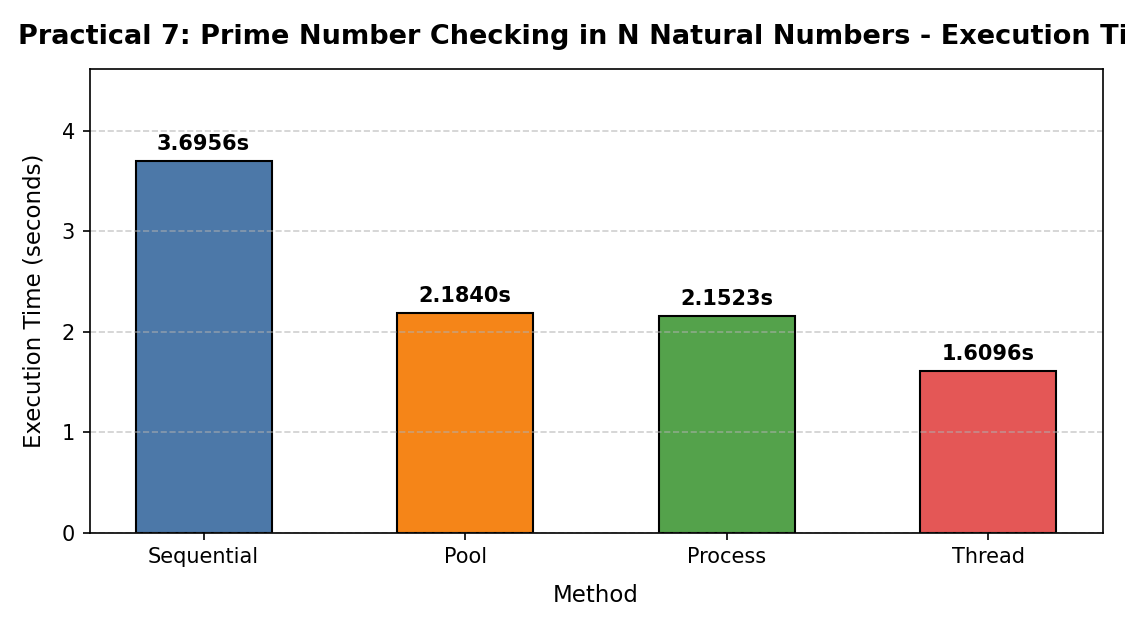

In [2]:
from IPython.display import Image, display
display(Image(filename='07_prime_numbers_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


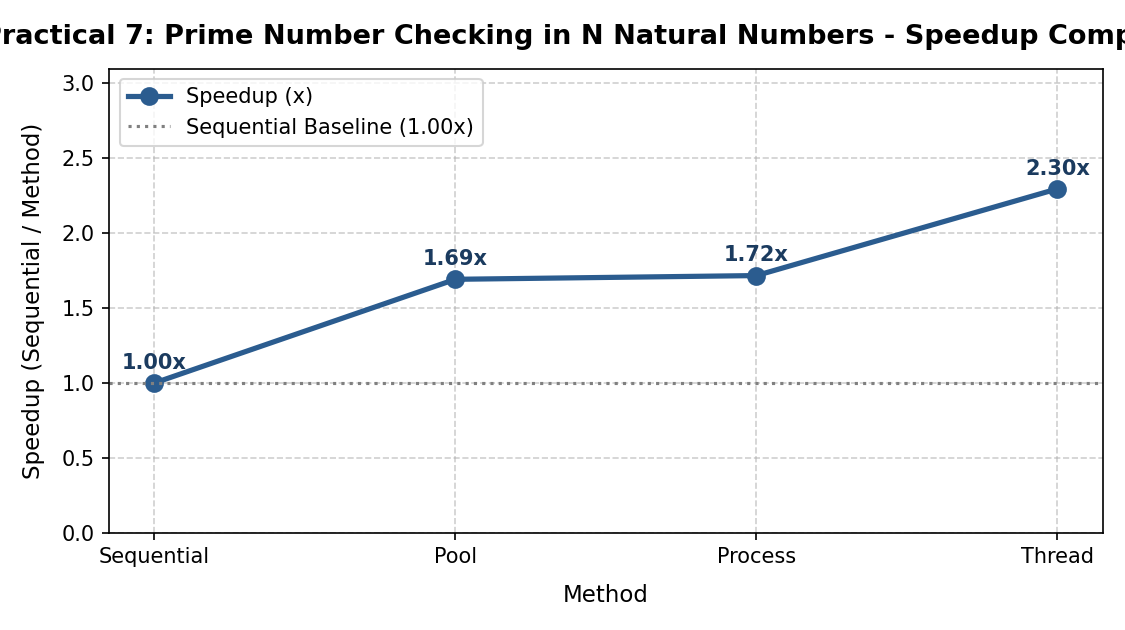

In [3]:
from IPython.display import Image, display
display(Image(filename='07_prime_numbers_speedup.png'))
